<a href="https://colab.research.google.com/github/sujalvengurlekar2000-glitch/CSL701-cs57_Machine-Learning-Lab/blob/main/cs57_ML_Experiment_10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : sujal vengurlekar

Batch : CS3


Roll Number : CS57



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Load the Mall Customer Segmentation dataset
df = pd.read_csv("Mall_Customers.csv")

# Display structural information and first 5 rows
print(f"Dataset Shape: {df.shape}")
df.info()
display(df.head())

Dataset Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
# Select target features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Verify scaling (mean should be ~0, variance ~1)
print("Mean of scaled features:", X_scaled.mean(axis=0))
print("Standard deviation of scaled features:", X_scaled.std(axis=0))
print("\nFirst 5 scaled samples:")
print(X_scaled[:5])

Mean of scaled features: [-2.13162821e-16 -1.46549439e-16]
Standard deviation of scaled features: [1. 1.]

First 5 scaled samples:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

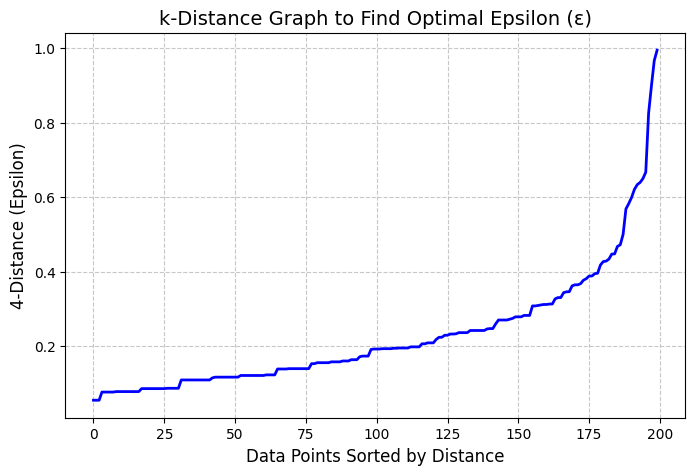

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# Typically, min_samples is set to 2 * dimensions = 4 for 2D data
min_samples = 4

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distance to the kth nearest neighbor (index 3 represents the 4th neighbor)
sorted_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(sorted_distances, color='blue', lw=2)
plt.title("k-Distance Graph to Find Optimal Epsilon (ε)", fontsize=14)
plt.xlabel("Data Points Sorted by Distance", fontsize=12)
plt.ylabel(f"{min_samples}-Distance (Epsilon)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:
# Task 4: Implement DBSCAN Clustering
# Based on the elbow of the k-distance plot, we choose eps = 0.35
epsilon_optimal = 0.35
min_samples_optimal = 4

# Instantiate and fit DBSCAN
dbscan = DBSCAN(eps=epsilon_optimal, min_samples=min_samples_optimal)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Add labels to original dataframe copy to evaluate classification
df_clustered = df.copy()
df_clustered['Cluster_Labels'] = dbscan_labels

print("DBSCAN training complete. Unique labels generated:", np.unique(dbscan_labels))

DBSCAN training complete. Unique labels generated: [-1  0  1  2  3  4  5  6]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Task 5: Evaluate DBSCAN Clustering

import numpy as np
from sklearn.metrics import silhouette_score

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

# Calculate silhouette score excluding noise points
mask = dbscan_labels != -1
valid_labels = dbscan_labels[mask]
valid_data = X_scaled[mask]

if 1 < len(set(valid_labels)) < len(valid_labels):
    score = silhouette_score(valid_data, valid_labels)
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated.")

Number of clusters: 7
Number of noise points: 16
Silhouette Score: 0.511


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
-1                    93.25                   65.81
 0                    25.24                   76.35
 1                    24.58                    9.58
 2                    22.43                   34.43
 3                    55.02                   48.33
 4                    80.50                   82.56
 5                    80.96                   12.78
 6                   101.00                   24.00


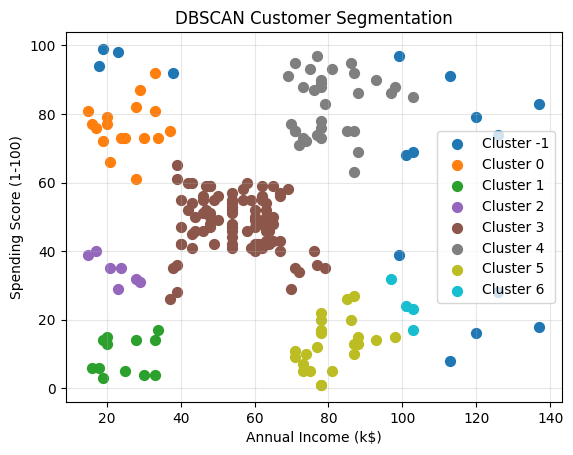

In [ ]:

# Task 6: Cluster Analysis and Visualization

import matplotlib.pyplot as plt
import pandas as pd

# Add cluster labels to the dataset
df['Cluster'] = dbscan_labels

# Display cluster statistics
print("Cluster Statistics:")
print(
    df.groupby('Cluster')[
        ['Annual Income (k$)', 'Spending Score (1-100)']
    ].mean().round(2)
)

# Visualize clusters
unique_labels = sorted(df['Cluster'].unique())
colors = plt.colormaps['tab10'].resampled(len(unique_labels))

for i, label in enumerate(unique_labels):
    cluster_data = df[df['Cluster'] == label]
    plt.scatter(
        cluster_data['Annual Income (k$)'],
        cluster_data['Spending Score (1-100)'],
        color=colors(i),
        label=f'Cluster {label}',
        s=50
    )

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('DBSCAN Customer Segmentation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.